# 05 · Three separate piles: train, dev and test

**The question this step answers:** which companies exist, and which pile does each belong to? The data is split into three piles that never share a company. Each pile has one job:

| Pile | Accounts | Used for |
|---|---|---|
| **train** | 12,000 | teaching the models that learn (XGBoost, random forest) |
| **dev** | 3,500 | making every choice: embedding model, thresholds, which method wins |
| **test** | 600 | the final exam: hand-checked, used once at the end |

*Why three:* a model judged on the accounts it learned from looks better than it is, and so does a choice made by looking at the exam. Each pile gets its own random seed, so no pile can repeat another's companies.

**Where it sits in the pipeline:** it puts notebooks 03 (rule-based companies) and 04 (LLM-written companies) together into the three files every later step reads: `data/generated/{train,dev,test}.jsonl`.

**The code:** `src/d1/datagen/splits.py`: `company_plan` (who is in each pile), `build_all` (builds and writes the three piles). Run it with `python -m d1.datagen build`.

In [1]:
import json
from collections import Counter
from random import Random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from d1.config import REPO_ROOT, load_config
from d1.datagen.standard_chart import load_standard_chart
from d1.evaluation.plotting import (
    BLUE_RAMP, COLORS, INK, INK_2, LANGUAGE_COLORS, MUTED, SINGLE, SOURCE_COLORS, SURFACE, apply_style, pct, short,
)

config = load_config()
chart = load_standard_chart(config.data.chart_path, expected=config.data.expected_groups)
by_code = {a.code: a for a in chart}
apply_style()
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_rows", 60)

from d1.datagen.schema import read_jsonl
from d1.datagen.splits import company_plan, normalize_name

splits = {s: read_jsonl(config.data.generated_dir / f"{s}.jsonl") for s in ["train", "dev", "test"]}
plans = {s: company_plan(s, config.data.splits[s], config.data.industries, config.data.languages) for s in splits}
display(pd.DataFrame({s: {"seed": c.seed, "rule-based companies": c.rule_companies, "accounts each": c.rule_accounts_per_company,
                          "LLM companies": c.llm_companies, "accounts each ": c.llm_accounts_per_company, "accounts in total": c.n_accounts}
                      for s, c in config.data.splits.items()}))

,train,dev,test
seed,3003,1001,2002
rule-based companies,200,40,8
accounts each,50,50,50
LLM companies,40,30,8
accounts each,50,50,25
accounts in total,12000,3500,600


## 1. The plan: which company is what

Before anything is generated, `company_plan` writes down every company of a pile: industry, language, rule-based or LLM, and code scheme. It does this with a fixed formula instead of random draws, so even the small test pile is balanced. With only 16 test companies, random draws could easily give 6 Dutch and 1 French. The test plan:

In [2]:
display(pd.DataFrame([s.model_dump(exclude={"split"}) for s in plans["test"]]).set_index("company_id"))

,industry,language,source,code_scheme,index,n_accounts
company_id,,,,,,
test-c000,software,nl,rules,pcmn,0,50
test-c001,construction,fr,rules,pcmn,1,50
test-c002,retail,en,rules,pcmn,2,50
test-c003,services,mixed,rules,pcmn,3,50
test-c004,software,fr,rules,legacy,4,50
test-c005,construction,en,rules,legacy,5,50
test-c006,retail,mixed,rules,legacy,6,50
test-c007,services,nl,rules,legacy,7,50
test-c008,software,en,llm,llm,8,25


How to read it: company *i* gets industry *i* mod 4 and language (*i* + *i* div 4) mod 4, so every industry meets every language. Within each source, it alternates between the company's own numbering and *legacy* codes in blocks of four. The result is in the table: 4 companies per language, half of each source with legacy codes.

## 2. What `build` does, step by step

1. **Check that every LLM company is frozen.** If one is missing, stop and name the `fetch-llm` command. `build` never calls an LLM.
2. **For each pile, go through its plan in order:**
   - a rule-based company is generated from the rules, with seed `pile seed × 1000 + its number` (notebook 03);
   - an LLM company is loaded from its frozen file (notebook 04), after checking that the file's industry and language match the plan.
3. **Mark test names seen before** (section 4).
4. **Write the three files.** Nothing is written unless all three piles build.

The result, per pile, source and language:

In [3]:
counts = pd.DataFrame([{"pile": s, "source": r.source, "language": r.language} for s, rows in splits.items() for r in rows])
display(pd.crosstab([counts["pile"], counts["source"]], counts["language"], margins=True, margins_name="total"))

language        en    fr  mixed    nl  total
pile  source                                
dev   llm      400   400    350   350   1500
      rules    500   500    500   500   2000
test  llm       50    50     50    50    200
      rules    100   100    100   100    400
train llm      500   500    499   500   1999
      rules   2500  2500   2500  2500  10000
total         4050  4050   3999  4000  16099

## 3. No company in two piles

Every company id carries its pile (`train-c007`, `dev-c007`), and each pile draws from its own seed. A quick check over all accounts:

In [4]:
companies = {s: {r.company_id for r in rows} for s, rows in splits.items()}
print("companies per pile:", {s: len(c) for s, c in companies.items()})
print("companies in two piles:", len((companies["train"] & companies["dev"]) | (companies["train"] & companies["test"]) | (companies["dev"] & companies["test"])))

companies per pile: {'train': 240, 'dev': 70, 'test': 16}
companies in two piles: 0


## 4. Test names that appeared before

Different companies can still write the *same name*: plenty of companies have an account just called "Goodwill" or "Terreinen". If a test account's name also occurs in train or dev, a method can get it right by remembering instead of understanding. So `build` marks every test account whose name, ignoring case, accents and punctuation, occurs in train or dev (`overlaps_dev`). The final report can then show results on the *unseen* test names separately.

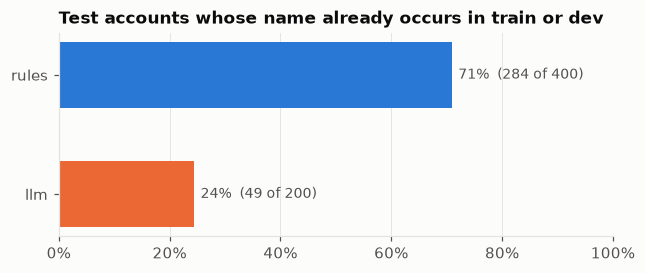

,test account,source,right group
0,Herwaarderingsmeerwaarden op materiële vaste activa,rules,121
1,Belastingvrije reserves,rules,132
2,VOORZIENINGEN VOOR PENSIOENEN EN SOORTGELIJKE VERPLICHTINGEN,rules,160
3,Voorz. voor overige risico's en kosten,rules,164
4,Bond loan - due within 12m,llm,421
5,Term deposit KBC 3-12m,llm,531
6,Petty cash Leuven,llm,570
7,Petty cash Ghent,llm,570


In [5]:
test = pd.DataFrame([{"source": r.source, "seen before": r.overlaps_dev} for r in splits["test"]])
share = test.groupby("source")["seen before"].mean().reindex(["rules", "llm"])
fig, ax = plt.subplots(figsize=(6.5, 2.4))
bars = ax.barh(share.index, share.values, color=[SOURCE_COLORS[s] for s in share.index], height=0.55)
ax.bar_label(bars, labels=[f"{v:.0%}  ({int(test[test['source'] == s]['seen before'].sum())} of {int((test['source'] == s).sum())})" for s, v in share.items()], padding=4, fontsize=9, color=INK_2)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(pct())
ax.grid(axis="y", visible=False)
ax.set_title("Test accounts whose name already occurs in train or dev")
plt.show()

seen = [r for r in splits["test"] if r.overlaps_dev]
display(pd.DataFrame([{"test account": r.name, "source": r.source, "right group": r.target_code} for r in seen[:4] + [r for r in seen if r.source == "llm"][:4]]))

Rule-based names overlap often, because they are noisy versions of the same 190 official names. LLM-written names overlap much less: every LLM company invents its own. One more reason the LLM-written test accounts are the honest measure of the mapper.

## 5. What is *not* happening

- **No LLM calls.** `build` only reads the frozen answers, so anyone can rebuild the three files offline, in seconds, and get identical results.
- **The files are not committed.** `data/generated/` is rebuilt from the seeds and the frozen files. Committing it would only duplicate what the code already guarantees.
- **The test labels are not final yet.** The LLM-written test accounts still carry the LLM's own labels here. Notebook 06 shows the hand check that corrects them, written to `test_checked.jsonl`, the only test file the evaluation reads.